In [1]:
import pandas as pd

In [3]:
df = pd.read_csv('C:/Users/RAJPATEL/OneDrive/Desktop/-Road-safe-analytics-/indian_roads_dataset.csv')
df.head()

,accident_id,city,state,latitude,longitude,date,time,hour,day_of_week,is_weekend,...,visibility,temperature,traffic_density,cause,accident_severity,vehicles_involved,casualties,is_peak_hour,festival,risk_score
0,0,Pune,Maharashtra,18.680827,73.930388,2023-10-22,5:00,5,Sunday,1,...,low,32,high,weather,fatal,2,2,0,NaN,0.85
1,1,Mumbai,Maharashtra,18.817732,72.790846,2023-05-21,4:00,4,Sunday,1,...,high,34,low,weather,major,4,3,0,NaN,0.10
2,2,Mumbai,Maharashtra,19.096889,72.819424,2024-07-10,13:00,13,Wednesday,0,...,low,21,medium,weather,minor,1,1,0,NaN,0.45
3,3,Chandigarh,Punjab,30.787805,76.847507,2025-03-30,11:00,11,Sunday,1,...,low,30,high,distraction,minor,5,2,0,NaN,0.65
4,4,Chennai,Tamil Nadu,12.965155,80.283313,2024-01-25,16:00,16,Thursday,0,...,high,24,low,distraction,minor,2,1,0,NaN,0.10


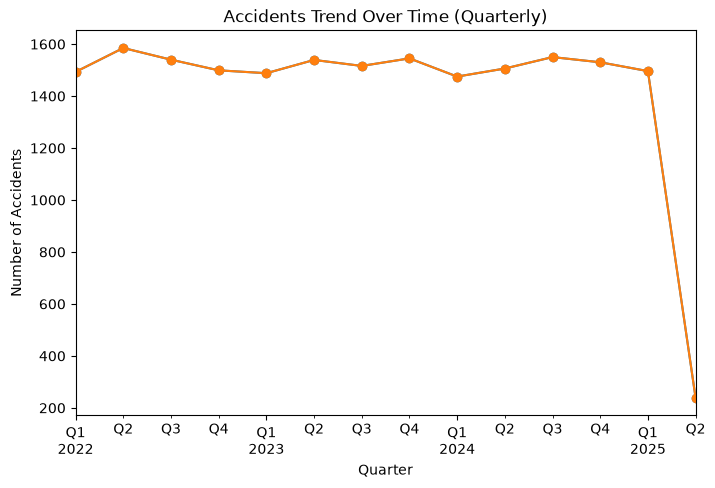

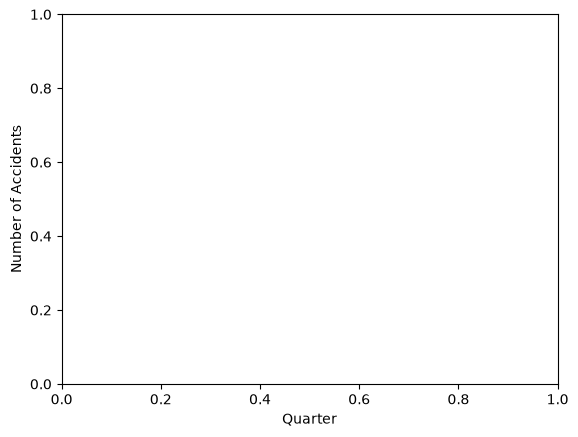

In [10]:
df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['Quarter'] = df['date'].dt.to_period('Q')
trend = df.groupby('Quarter').size()
trend.plot(kind='line', marker='o', figsize=(8,5))
import matplotlib.pyplot as plt

df['date'] = pd.to_datetime(df['date'], errors='coerce')
df['Quarter'] = df['date'].dt.to_period('Q')
trend = df.groupby('Quarter').size()
trend.plot(kind='line', marker='o', figsize=(8,5))
plt.title("Accidents Trend Over Time (Quarterly)")
plt.ylabel("Number of Accidents")
plt.xlabel("Quarter")
plt.show()
plt.ylabel("Number of Accidents")
plt.xlabel("Quarter")
plt.show()

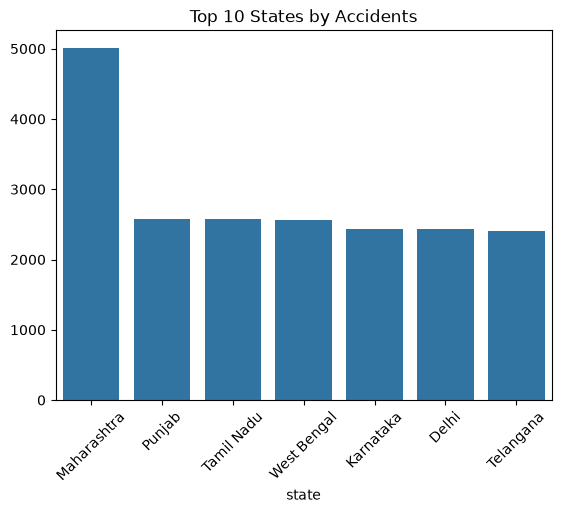

In [15]:
import seaborn as sns

state_counts = df['state'].value_counts().head(10)
sns.barplot(x=state_counts.index, y=state_counts.values)
plt.title("Top 10 States by Accidents")
plt.xticks(rotation=45)
plt.show()

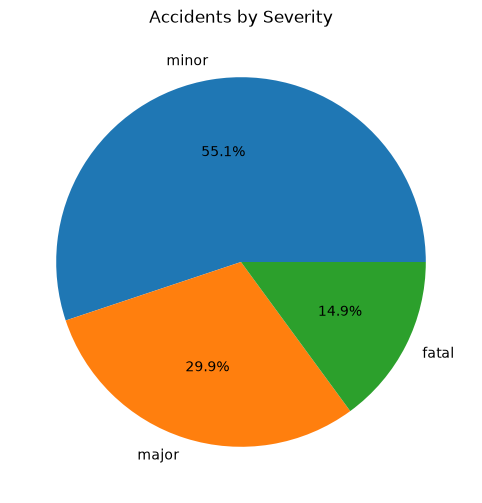

In [16]:
severity_col = 'accident_severity'
severity_counts = df[severity_col].value_counts()
severity_counts.plot(kind='pie', autopct='%1.1f%%', figsize=(6,6))
plt.title("Accidents by Severity")
plt.ylabel("")
plt.show()

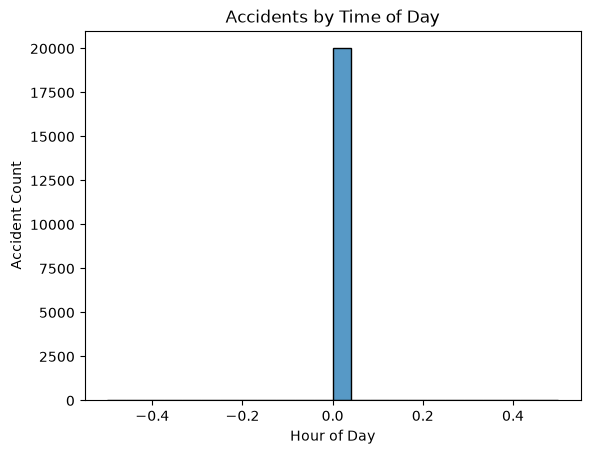

In [22]:
df['Hour'] = df['Date'].dt.hour
sns.histplot(df['Hour'], bins=24, kde=False)
plt.title("Accidents by Time of Day")
plt.xlabel("Hour of Day")
plt.ylabel("Accident Count")
plt.show()

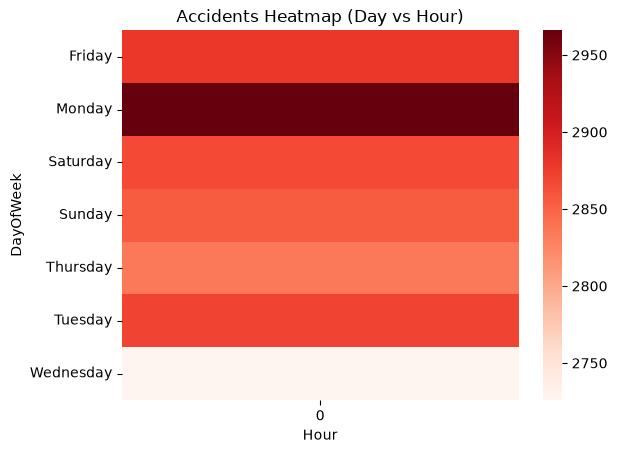

In [21]:
df['Date'] = pd.to_datetime(df['date'], errors='coerce')
df['DayOfWeek'] = df['Date'].dt.day_name()
df['Hour'] = df['Date'].dt.hour
heatmap_data = df.groupby([df['DayOfWeek'], df['Hour']]).size().unstack(fill_value=0)
sns.heatmap(heatmap_data, cmap="Reds")
plt.title("Accidents Heatmap (Day vs Hour)")
plt.show()